# Ship Crew Size Prediction

Estimate a cruise ship’s crew size from its age, tonnage, passenger capacity, length, and number of cabins.

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/niclasko/niclasko.github.io/master/data/cruise_ship_info.csv"
df = pd.read_csv(url)

print("Dataset size:", df.shape)
display(df.head())

Dataset size: (158, 9)


,Ship_name,Cruise_line,Age,Tonnage,passengers,length,cabins,passenger_density,crew
0,Journey,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55
1,Quest,Azamara,6,30.277,6.94,5.94,3.55,42.64,3.55
2,Celebration,Carnival,26,47.262,14.86,7.22,7.43,31.80,6.70
3,Conquest,Carnival,11,110.000,29.74,9.53,14.88,36.99,19.10
4,Destiny,Carnival,17,101.353,26.42,8.92,13.21,38.36,10.00


In [2]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary:")
display(df.describe())

Columns:
['Ship_name', 'Cruise_line', 'Age', 'Tonnage', 'passengers', 'length', 'cabins', 'passenger_density', 'crew']

Missing values:
Ship_name            0
Cruise_line          0
Age                  0
Tonnage              0
passengers           0
length               0
cabins               0
passenger_density    0
crew                 0
dtype: int64

Summary:


,Age,Tonnage,passengers,length,cabins,passenger_density,crew
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,15.689873,71.284671,18.457405,8.130633,8.830000,39.900949,7.794177
std,7.615691,37.229540,9.677095,1.793474,4.471417,8.639217,3.503487
min,4.000000,2.329000,0.660000,2.790000,0.330000,17.700000,0.590000
25%,10.000000,46.013000,12.535000,7.100000,6.132500,34.570000,5.480000
50%,14.000000,71.899000,19.500000,8.555000,9.570000,39.085000,8.150000
75%,20.000000,90.772500,24.845000,9.510000,10.885000,44.185000,9.990000
max,48.000000,220.000000,54.000000,11.820000,27.000000,71.430000,21.000000


In [3]:
# Use ship characteristics to predict crew size.
# Ship_name is omitted so the model learns from ship features, not names.
X = df.drop(columns=["crew", "Ship_name"])
y = df["crew"]

print("Input features:", X.columns.tolist())
print("Target:", y.name)
print("Rows:", len(X))

Input features: ['Cruise_line', 'Age', 'Tonnage', 'passengers', 'length', 'cabins', 'passenger_density']
Target: crew
Rows: 158


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 126
Test rows: 32


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

categorical_features = ["Cruise_line"]
numeric_features = X.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("category", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Baseline model trained.")

Baseline model trained.


In [6]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_predictions = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, linear_predictions)
rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
r2 = r2_score(y_test, linear_predictions)

print(f"MAE:  {mae:.3f} dataset units")
print(f"RMSE: {rmse:.3f} dataset units")
print(f"R²:   {r2:.3f}")

MAE:  0.499 dataset units
RMSE: 0.771 dataset units
R²:   0.954


In [7]:
from sklearn.ensemble import RandomForestRegressor

forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ))
])

forest_model.fit(X_train, y_train)

print("Random Forest model trained.")

Random Forest model trained.


In [8]:
forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

print(f"Random Forest MAE:  {forest_mae:.3f} dataset units")
print(f"Random Forest RMSE: {forest_rmse:.3f} dataset units")
print(f"Random Forest R²:   {forest_r2:.3f}")

Random Forest MAE:  0.979 dataset units
Random Forest RMSE: 1.765 dataset units
Random Forest R²:   0.759


In [9]:
from sklearn.model_selection import GroupKFold, cross_val_score

group_cv = GroupKFold(n_splits=5)
groups = df["Cruise_line"]

linear_cv_mae = -cross_val_score(
    linear_model, X, y,
    cv=group_cv,
    groups=groups,
    scoring="neg_mean_absolute_error"
)

forest_cv_mae = -cross_val_score(
    forest_model, X, y,
    cv=group_cv,
    groups=groups,
    scoring="neg_mean_absolute_error"
)

print(f"Linear Regression grouped CV MAE: {linear_cv_mae.mean():.3f} ± {linear_cv_mae.std():.3f}")
print(f"Random Forest grouped CV MAE:      {forest_cv_mae.mean():.3f} ± {forest_cv_mae.std():.3f}")

Linear Regression grouped CV MAE: 0.705 ± 0.190
Random Forest grouped CV MAE:      0.855 ± 0.401


In [10]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Test MAE": [mae, forest_mae],
    "Test RMSE": [rmse, forest_rmse],
    "Test R²": [r2, forest_r2],
    "Grouped CV MAE (mean)": [linear_cv_mae.mean(), forest_cv_mae.mean()],
    "Grouped CV MAE (std)": [linear_cv_mae.std(), forest_cv_mae.std()],
})

display(comparison.round(3))

,Model,Test MAE,Test RMSE,Test R²,Grouped CV MAE (mean),Grouped CV MAE (std)
0,Linear Regression,0.499,0.771,0.954,0.705,0.190
1,Random Forest,0.979,1.765,0.759,0.855,0.401


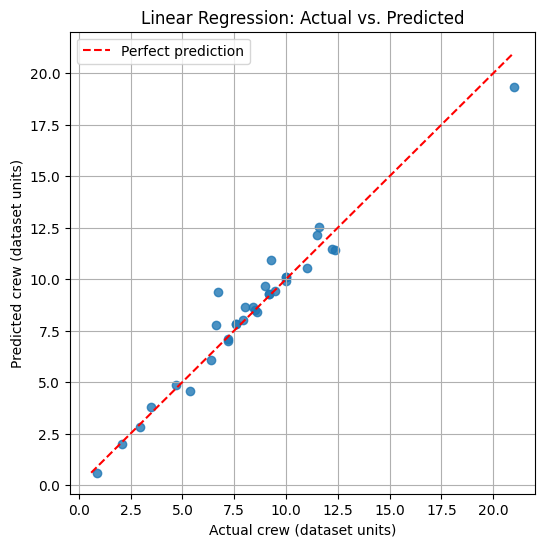

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y_test, linear_predictions, alpha=0.8)

low = min(y_test.min(), linear_predictions.min())
high = max(y_test.max(), linear_predictions.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Actual crew (dataset units)")
plt.ylabel("Predicted crew (dataset units)")
plt.title("Linear Regression: Actual vs. Predicted")
plt.legend()
plt.grid(True)
plt.show()

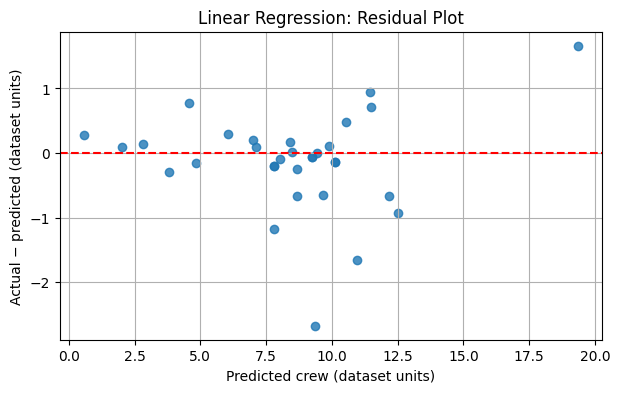

In [12]:
residuals = y_test - linear_predictions

plt.figure(figsize=(7, 4))
plt.scatter(linear_predictions, residuals, alpha=0.8)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted crew (dataset units)")
plt.ylabel("Actual − predicted (dataset units)")
plt.title("Linear Regression: Residual Plot")
plt.grid(True)
plt.show()


In [13]:
prediction_review = pd.DataFrame({
    "Ship": df.loc[X_test.index, "Ship_name"],
    "Actual crew members": (y_test * 100).round().astype(int),
    "Predicted crew members": (linear_predictions * 100).round().astype(int),
})

prediction_review["Absolute error"] = (
    prediction_review["Actual crew members"]
    - prediction_review["Predicted crew members"]
).abs()

display(prediction_review.sort_values("Absolute error", ascending=False).head(10))

,Ship,Actual crew members,Predicted crew members,Absolute error
30,Solstice,670,938,268
134,Oasis,2100,1934,166
18,Pride,930,1095,165
140,Vision,660,779,119
109,Saphire,1238,1144,94
15,Liberty*,1160,1253,93
69,Melody,535,458,77
96,Ventura,1220,1149,71
65,Zuiderdam,800,867,67
9,Freedom,1150,1216,66


In [14]:
new_ship = pd.DataFrame([{
    "Cruise_line": "Royal_Caribbean",
    "Age": 5,
    "Tonnage": 200,
    "passengers": 50,
    "length": 11.0,
    "cabins": 25.0,
    "passenger_density": 40.0
}])

predicted_crew_units = linear_model.predict(new_ship)[0]
predicted_crew_members = round(predicted_crew_units * 100)

print(f"Estimated crew: about {predicted_crew_members:,} people")

Estimated crew: about 1,761 people


In [15]:
final_model = linear_model
final_model.fit(X, y)

print("Final model trained on all ships.")

Final model trained on all ships.


In [16]:
final_crew_units = final_model.predict(new_ship)[0]
final_crew_members = round(final_crew_units * 100)

print(f"Final estimated crew: about {final_crew_members:,} people")

Final estimated crew: about 1,850 people


## Results

I compared Linear Regression and Random Forest using a held-out test set and 5-fold cross-validation grouped by cruise line. Linear Regression had the lower grouped CV MAE: 0.705 dataset units (about 71 crew members), compared with 0.855 units for Random Forest.

For the example ship, the final Linear Regression model estimated about 1,850 crew members.

## Limitations

The dataset contains 158 cruise ships, so results may not generalize to other vessel types or ships with very different designs. This estimate is for a portfolio project and should not be used as a required or safety-approved crew complement.